<sub>**The Annotated ML Handbook** · Part VII: ML for Research · by Mahir Absar Khan</sub>

# Chapter 29: The ML research protocol: a complete worked study

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-7-ml-for-research/29-research-protocol.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

# The ML research protocol: a complete worked study

This chapter strings everything together into a protocol you can follow for a thesis chapter or a paper, and runs it end to end on a real dataset. Each step says **what to do**, **why**, and **what to report**. Copy the structure, swap in your data.

**The study.** Can routinely measured cell-nucleus features from fine-needle aspirate images classify breast masses as malignant or benign, and which features drive the prediction? (Wisconsin Diagnostic Breast Cancer data, 569 cases, bundled with scikit-learn.)

## 29.1 The protocol at a glance · *Beginner*

> **📖 Definitions**
>
> **Research protocol**: a written, step-by-step plan for a study, fixed before analysis, covering the question, data, methods and how results will be judged.
>
> **Primary metric**: the single metric chosen in advance to judge success. Others are reported as secondary.


| Step | Do | Report |
|---|---|---|
| 1. Question | Define the target, the unit of analysis, the population, the primary metric, and what "useful" means | Objective, outcome definition, primary metric |
| 2. Data | Document the source, variables, missingness and exclusions | Data source, sample size, a table of characteristics |
| 3. Explore | Distributions, class balance, correlations, oddities, using training data for decisions | Key descriptive statistics, any data issues found |
| 4. Split | Lock a test set away (stratified, grouped or temporal as appropriate) | Split method, sizes, seed |
| 5. Baselines | Dummy model and a simple, interpretable model | Baseline performance |
| 6. Compare | Candidate pipelines under repeated cross-validation | Mean ± SD for every candidate, not just the winner |
| 7. Tune | Hyperparameter search inside CV; nested CV if there is no test set | Search space, method, chosen values |
| 8. Test | Evaluate the final model on the test set once, with confidence intervals | Test metrics with 95% CIs, confusion matrix, curves |
| 9. Interpret | Permutation importance, PDP/SHAP, error analysis, checked for stability | Top features, their direction, caveats |
| 10. Robustness | Seeds, calibration, learning curve, subgroups, sensitivity analyses | Variability and limitations |
| 11. Reproduce | Save code, environment, seeds, model; write it up | Software versions, code availability |

## 29.2 Step 1: define the question before touching the data · *Beginner*

Write these down first. They stop you from moving the goalposts after seeing results.

- **Target**: malignant (1) vs benign (0), from histopathology.
- **Unit of analysis**: one mass per patient (so a random split is valid; with repeated measures you would group by patient).
- **Primary metric**: ROC AUC (threshold-free ranking quality). **Secondary**: sensitivity (recall for malignant) at a threshold chosen on training data, specificity, balanced accuracy, Brier score.
- **What counts as useful**: high sensitivity, because a missed cancer is costlier than a false alarm.

> **🔬 Research practice** · **Pre-specify**
>
> Writing the analysis plan (metric, split, candidate models, tuning budget) before modelling, ideally with a timestamp (OSF, a dated Git commit), is the ML equivalent of pre-registration. It is your best defence against accidental p-hacking ("trying things until something works").

## 29.3 Step 2: load and document the data · *Beginner*

**Data and a characteristics table**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

RANDOM_STATE = 2026
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
df["malignant"] = 1 - df.pop("target")
print(df.shape)
print("missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print(df["malignant"].value_counts().rename({0: "benign", 1: "malignant"}))
table1 = (df.groupby("malignant")[["mean radius", "mean texture", "mean concave points", "worst area"]]
            .agg(["mean", "std"]).round(2).T)
table1.columns = ["benign", "malignant"]
print(table1)

(569, 31)
missing values: 0 | duplicate rows: 0
malignant
benign       357
malignant    212
Name: count, dtype: int64
                          benign  malignant
mean radius         mean   12.15      17.46
                    std     1.78       3.20
mean texture        mean   17.91      21.60
                    std     4.00       3.78
mean concave points mean    0.03       0.09
                    std     0.02       0.03
worst area          mean  558.90    1422.29
                    std   163.60     597.97


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Import pandas (the table library) under the short name <code>pd</code>.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Import Matplotlib&#x27;s plotting interface under the short name <code>plt</code>.</td></tr>
<tr><td><code>import seaborn as sns</code></td><td>Import Seaborn (statistical plots built on Matplotlib) under the short name <code>sns</code>.</td></tr>
<tr><td><code>from sklearn.datasets import load_breast_cancer</code></td><td>Import <code>load_breast_cancer</code> from scikit-learn&#x27;s <code>datasets</code> module.</td></tr>
<tr><td><code>RANDOM_STATE = 2026</code></td><td>ONE seed constant, used everywhere, reported in the paper.</td></tr>
<tr><td><code>raw = load_breast_cancer(as_frame=True)</code></td><td>Load the data as pandas objects.</td></tr>
<tr><td><code>df = raw.frame.copy()</code></td><td>One DataFrame with features and target together.</td></tr>
<tr><td><code>df[&quot;malignant&quot;] = 1 - df.pop(&quot;target&quot;)</code></td><td>pop removes &quot;target&quot;; we recode so 1 = malignant (the positive class).</td></tr>
<tr><td><code>print(df.shape)</code></td><td>Display the value of <code>df.shape</code>.</td></tr>
<tr><td><code>print(&quot;missing values:&quot;, int(df.isna().sum().sum()), &quot;| duplicate rows:&quot;, int(df.duplicated().sum()))</code></td><td>Data-quality checks: both are 0 here.</td></tr>
<tr><td><code>print(df[&quot;malignant&quot;].value_counts().rename({0: &quot;benign&quot;, 1: &quot;malignant&quot;}))</code></td><td>Class counts with readable labels.</td></tr>
<tr><td><code>table1 = (df.groupby(&quot;malignant&quot;)[[&quot;mean radius&quot;, &quot;mean texture&quot;, &quot;mean concave points&quot;, &quot;worst area&quot;]]</code></td><td>Group by class and pick four key variables...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;.agg([&quot;mean&quot;, &quot;std&quot;]).round(2).T)</code></td><td>A compact &quot;Table 1&quot;: mean (SD) of key variables by class.</td></tr>
<tr><td><code>table1.columns = [&quot;benign&quot;, &quot;malignant&quot;]</code></td><td>Readable column names.</td></tr>
<tr><td><code>print(table1)</code></td><td>Display the value of <code>table1</code>.</td></tr>
</table>
</details>

## 29.4 Step 3: exploratory analysis · *Beginner*

**Distributions and correlations**

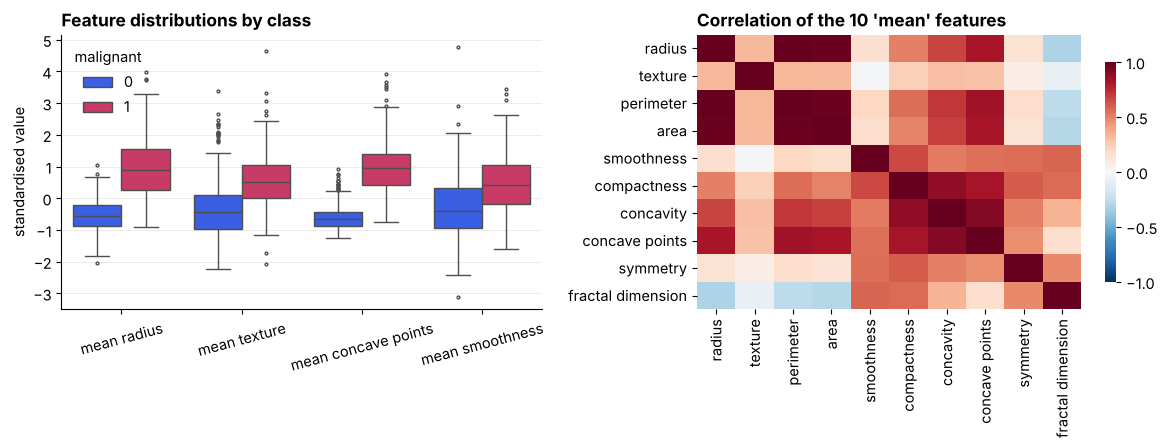

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
long = df.melt(id_vars="malignant", value_vars=["mean radius", "mean texture", "mean concave points", "mean smoothness"])
long["z"] = long.groupby("variable")["value"].transform(lambda s: (s - s.mean()) / s.std())
sns.boxplot(data=long, x="variable", y="z", hue="malignant", ax=axes[0], fliersize=2)
axes[0].set(xlabel="", ylabel="standardised value", title="Feature distributions by class")
axes[0].tick_params(axis="x", rotation=15)
corr = df.drop(columns="malignant").iloc[:, :10].corr()
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1], cbar_kws={"shrink": 0.8},
            xticklabels=[c.replace("mean ", "") for c in corr.columns], yticklabels=[c.replace("mean ", "") for c in corr.columns])
axes[1].set_title("Correlation of the 10 'mean' features"); axes[1].grid(False)
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))</code></td><td>Two panels.</td></tr>
<tr><td><code>long = df.melt(id_vars=&quot;malignant&quot;, value_vars=[&quot;mean radius&quot;, &quot;mean texture&quot;, &quot;mean concave points&quot;, &quot;mean smoothness&quot;])</code></td><td>Reshape four features to long format for Seaborn.</td></tr>
<tr><td><code>long[&quot;z&quot;] = long.groupby(&quot;variable&quot;)[&quot;value&quot;].transform(lambda s: (s - s.mean()) / s.std())</code></td><td>Standardise so features share one axis.</td></tr>
<tr><td><code>sns.boxplot(data=long, x=&quot;variable&quot;, y=&quot;z&quot;, hue=&quot;malignant&quot;, ax=axes[0], fliersize=2)</code></td><td>One pair of boxes (benign vs malignant) per feature.</td></tr>
<tr><td><code>axes[0].set(xlabel=&quot;&quot;, ylabel=&quot;standardised value&quot;, title=&quot;Feature distributions by class&quot;)</code></td><td>Labels.</td></tr>
<tr><td><code>axes[0].tick_params(axis=&quot;x&quot;, rotation=15)</code></td><td>Tilt the feature names.</td></tr>
<tr><td><code>corr = df.drop(columns=&quot;malignant&quot;).iloc[:, :10].corr()</code></td><td>Correlations among the first 10 features.</td></tr>
<tr><td><code>sns.heatmap(corr, cmap=&quot;RdBu_r&quot;, vmin=-1, vmax=1, ax=axes[1], cbar_kws={&quot;shrink&quot;: 0.8},</code></td><td>Heatmap on a fixed -1..1 scale...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;xticklabels=[c.replace(&quot;mean &quot;, &quot;&quot;) for c in corr.columns], yticklabels=[c.replace(&quot;mean &quot;, &quot;&quot;) for c in corr.columns])</code></td><td>...with shorter tick labels.</td></tr>
<tr><td><code>axes[1].set_title(&quot;Correlation of the 10 &#x27;mean&#x27; features&quot;); axes[1].grid(False)</code></td><td>Title, no grid.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

> **⚠️ Pitfall** · **Explore with care**
>
> Looking at the *whole* dataset to understand variables and spot errors is fine. Using it to **choose** features or thresholds is not: those choices must be made on training data. A safe habit is to split first and run detailed exploration on the training set only.

## 29.5 Step 4: split and lock away the test set · *Beginner*

> **📖 Definitions**
>
> **Hold-out set**: data set aside from all model development and used only for final evaluation (the test set).

**Stratified hold-out split**

In [4]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="malignant")
y = df["malignant"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"train n={len(y_train)} ({y_train.mean():.1%} malignant) | test n={len(y_test)} ({y_test.mean():.1%} malignant)")

train n=426 (37.3% malignant) | test n=143 (37.1% malignant)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import train_test_split</code></td><td>Import <code>train_test_split</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>X = df.drop(columns=&quot;malignant&quot;)</code></td><td>Features.</td></tr>
<tr><td><code>y = df[&quot;malignant&quot;]</code></td><td>Target.</td></tr>
<tr><td><code>X_train, X_test, y_train, y_test = train_test_split(</code></td><td>Split into training and test sets...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)</code></td><td>25% test, class balance preserved.</td></tr>
<tr><td><code>print(f&quot;train n={len(y_train)} ({y_train.mean():.1%} malignant) | test n={len(y_test)} ({y_test.mean():.1%} malignant)&quot;)</code></td><td>Sizes and class balance of each part.</td></tr>
</table>
</details>

## 29.6 Steps 5–6: baselines and candidate models under repeated CV · *Intermediate*

**Compare candidates with identical, repeated CV**

In [5]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
candidates = {
    "Dummy": DummyClassifier(strategy="prior"),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC()),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "HistGB": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
scoring = {"auc": "roc_auc", "bal_acc": "balanced_accuracy", "recall": "recall"}
cv_scores, rows = {}, []
for name, est in candidates.items():
    r = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_scores[name] = r["test_auc"]
    rows.append({"model": name, **{f"{k} mean": r[f"test_{k}"].mean() for k in scoring},
                 "auc sd": r["test_auc"].std()})
summary = pd.DataFrame(rows).sort_values("auc mean", ascending=False).round(4)
print(summary.to_string(index=False))

       model  auc mean  bal_acc mean  recall mean  auc sd
      LogReg    0.9978        0.9726       0.9586  0.0026
     SVM-RBF    0.9969        0.9687       0.9486  0.0034
      HistGB    0.9944        0.9524       0.9310  0.0051
         kNN    0.9932        0.9553       0.9173  0.0070
RandomForest    0.9928        0.9558       0.9371  0.0084
       Dummy    0.5000        0.5000       0.0000  0.0000


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate</code></td><td>Import <code>RepeatedStratifiedKFold</code> and <code>cross_validate</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>from sklearn.pipeline import make_pipeline</code></td><td>Import <code>make_pipeline</code> from scikit-learn&#x27;s <code>pipeline</code> module.</td></tr>
<tr><td><code>from sklearn.preprocessing import StandardScaler</code></td><td>Import <code>StandardScaler</code> from scikit-learn&#x27;s <code>preprocessing</code> module.</td></tr>
<tr><td><code>from sklearn.dummy import DummyClassifier</code></td><td>Import <code>DummyClassifier</code> from scikit-learn&#x27;s <code>dummy</code> module.</td></tr>
<tr><td><code>from sklearn.linear_model import LogisticRegression</code></td><td>Import <code>LogisticRegression</code> from scikit-learn&#x27;s <code>linear_model</code> module.</td></tr>
<tr><td><code>from sklearn.neighbors import KNeighborsClassifier</code></td><td>Import <code>KNeighborsClassifier</code> from scikit-learn&#x27;s <code>neighbors</code> module.</td></tr>
<tr><td><code>from sklearn.svm import SVC</code></td><td>Import <code>SVC</code> from scikit-learn&#x27;s <code>svm</code> module.</td></tr>
<tr><td><code>from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier</code></td><td>Import <code>RandomForestClassifier</code> and <code>HistGradientBoostingClassifier</code> from scikit-learn&#x27;s <code>ensemble</code> module.</td></tr>
<tr><td><code>cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)</code></td><td>25 train/validation splits, IDENTICAL for every model.</td></tr>
<tr><td><code>candidates = {</code></td><td>The candidate models:</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;Dummy&quot;: DummyClassifier(strategy=&quot;prior&quot;),</code></td><td>Baseline.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;LogReg&quot;: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),</code></td><td>Scaled logistic regression.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;kNN&quot;: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),</code></td><td>Scaled kNN, 9 neighbours.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;SVM-RBF&quot;: make_pipeline(StandardScaler(), SVC()),</code></td><td>Scaled RBF support vector machine.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;RandomForest&quot;: RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),</code></td><td>Random forest.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;HistGB&quot;: HistGradientBoostingClassifier(random_state=RANDOM_STATE),</code></td><td>Gradient boosting.</td></tr>
<tr><td><code>}</code></td><td>Close the dictionary opened above.</td></tr>
<tr><td><code>scoring = {&quot;auc&quot;: &quot;roc_auc&quot;, &quot;bal_acc&quot;: &quot;balanced_accuracy&quot;, &quot;recall&quot;: &quot;recall&quot;}</code></td><td>Short name -&gt; scikit-learn scorer.</td></tr>
<tr><td><code>cv_scores, rows = {}, []</code></td><td>Per-model AUC arrays, and summary rows.</td></tr>
<tr><td><code>for name, est in candidates.items():</code></td><td>Loop over <code>candidates.items()</code>, naming each item <code>name, est</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;r = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)</code></td><td>Cross-validate this candidate on the 25 splits.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;cv_scores[name] = r[&quot;test_auc&quot;]</code></td><td>Keep all 25 AUCs for plotting and statistical comparison.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;rows.append({&quot;model&quot;: name, **{f&quot;{k} mean&quot;: r[f&quot;test_{k}&quot;].mean() for k in scoring},</code></td><td>Mean of each metric...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;auc sd&quot;: r[&quot;test_auc&quot;].std()})</code></td><td>...plus the spread of AUC.</td></tr>
<tr><td><code>summary = pd.DataFrame(rows).sort_values(&quot;auc mean&quot;, ascending=False).round(4)</code></td><td>Summary table, best AUC first.</td></tr>
<tr><td><code>print(summary.to_string(index=False))</code></td><td>Print it.</td></tr>
</table>
</details>

**Show the spread, not just the mean**

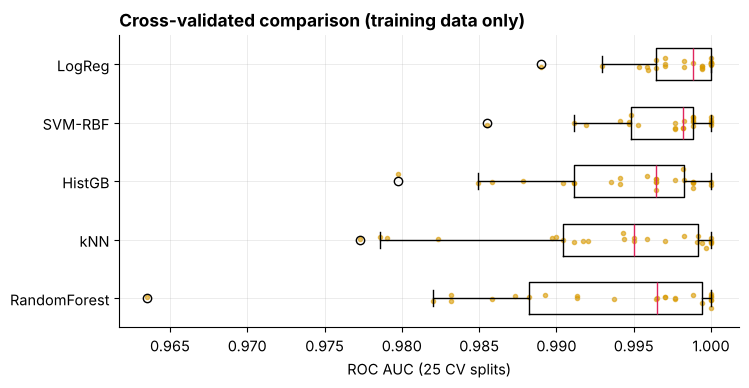

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = summary["model"].tolist()[::-1]
order = [m for m in order if m != "Dummy"]
ax.boxplot([cv_scores[m] for m in order], orientation="horizontal", tick_labels=order, widths=0.55)
for i, m in enumerate(order, start=1):
    ax.scatter(cv_scores[m], np.random.default_rng(i).normal(i, 0.06, len(cv_scores[m])), s=9, alpha=0.6, color="#d99a00")
ax.set(xlabel="ROC AUC (25 CV splits)", title="Cross-validated comparison (training data only)")
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>fig, ax = plt.subplots(figsize=(8, 3.8))</code></td><td>One panel.</td></tr>
<tr><td><code>order = summary[&quot;model&quot;].tolist()[::-1]</code></td><td>Worst first, so the best is drawn at the top.</td></tr>
<tr><td><code>order = [m for m in order if m != &quot;Dummy&quot;]</code></td><td>The dummy (AUC 0.5) would squash the axis.</td></tr>
<tr><td><code>ax.boxplot([cv_scores[m] for m in order], orientation=&quot;horizontal&quot;, tick_labels=order, widths=0.55)</code></td><td>One horizontal box per model.</td></tr>
<tr><td><code>for i, m in enumerate(order, start=1):</code></td><td>Loop over <code>enumerate(order, start=1)</code>, naming each item <code>i, m</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.scatter(cv_scores[m], np.random.default_rng(i).normal(i, 0.06, len(cv_scores[m])), s=9, alpha=0.6, color=&quot;#d99a00&quot;)</code></td><td>Jittered raw points.</td></tr>
<tr><td><code>ax.set(xlabel=&quot;ROC AUC (25 CV splits)&quot;, title=&quot;Cross-validated comparison (training data only)&quot;)</code></td><td>Labels.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 29.7 Step 7: tune the chosen model · *Intermediate*

Logistic regression is near the top, fast, and interpretable, so it is our primary model. We tune its regularisation strength `C` (and penalty type) inside CV.

**Grid search on training data**

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, solver="liblinear"))
grid = {"logisticregression__C": np.logspace(-3, 2, 11),
        "logisticregression__l1_ratio": [0.0, 1.0]}
search = GridSearchCV(pipe, grid, scoring="roc_auc",
                      cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
search.fit(X_train, y_train)
best_C = search.best_params_["logisticregression__C"]
print("best:", {"C": round(float(best_C), 4), "l1_ratio": search.best_params_["logisticregression__l1_ratio"]},
      "| CV AUC:", round(search.best_score_, 4))
final_model = search.best_estimator_

best: {'C': 1.0, 'l1_ratio': 1.0} | CV AUC: 0.9978


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import GridSearchCV, StratifiedKFold</code></td><td>Import <code>GridSearchCV</code> and <code>StratifiedKFold</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, solver=&quot;liblinear&quot;))</code></td><td>liblinear handles both L1 and L2 penalties and is fast on small data.</td></tr>
<tr><td><code>grid = {&quot;logisticregression__C&quot;: np.logspace(-3, 2, 11),</code></td><td>11 values of C from 0.001 to 100...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;logisticregression__l1_ratio&quot;: [0.0, 1.0]}</code></td><td>l1_ratio=0 -&gt; L2 (ridge-like), 1 -&gt; L1 (lasso-like, sparse).</td></tr>
<tr><td><code>search = GridSearchCV(pipe, grid, scoring=&quot;roc_auc&quot;,</code></td><td>Grid search maximising ROC AUC...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)</code></td><td>...with stratified 5-fold CV.</td></tr>
<tr><td><code>search.fit(X_train, y_train)</code></td><td>Run the search on training data only.</td></tr>
<tr><td><code>best_C = search.best_params_[&quot;logisticregression__C&quot;]</code></td><td>The chosen C.</td></tr>
<tr><td><code>print(&quot;best:&quot;, {&quot;C&quot;: round(float(best_C), 4), &quot;l1_ratio&quot;: search.best_params_[&quot;logisticregression__l1_ratio&quot;]},</code></td><td>Report the chosen values...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;| CV AUC:&quot;, round(search.best_score_, 4))</code></td><td>...and their CV score.</td></tr>
<tr><td><code>final_model = search.best_estimator_</code></td><td>Already refitted on the full training set.</td></tr>
</table>
</details>

### 29.7.1 Choose the operating threshold on training data · *Intermediate*

**A threshold for ≥ 95% sensitivity, from out-of-fold predictions**

In [8]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(final_model, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                        method="predict_proba")[:, 1]
thresholds = np.linspace(0.01, 0.99, 99)
sens = np.array([((oof >= t) & (y_train == 1)).sum() / (y_train == 1).sum() for t in thresholds])
threshold = float(thresholds[sens >= 0.95].max())
print(f"chosen threshold = {threshold:.2f}")

chosen threshold = 0.62


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import cross_val_predict</code></td><td>Import <code>cross_val_predict</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>oof = cross_val_predict(final_model, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),</code></td><td>Out-of-fold probabilities for the training cases...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;method=&quot;predict_proba&quot;)[:, 1]</code></td><td>Each training case predicted by a model that did not see it.</td></tr>
<tr><td><code>thresholds = np.linspace(0.01, 0.99, 99)</code></td><td>Candidate thresholds 0.01, 0.02, ..., 0.99.</td></tr>
<tr><td><code>sens = np.array([((oof &gt;= t) &amp; (y_train == 1)).sum() / (y_train == 1).sum() for t in thresholds])</code></td><td>Sensitivity at each threshold.</td></tr>
<tr><td><code>threshold = float(thresholds[sens &gt;= 0.95].max())</code></td><td>The highest threshold that still gives &gt;= 95% sensitivity.</td></tr>
<tr><td><code>print(f&quot;chosen threshold = {threshold:.2f}&quot;)</code></td><td>The threshold we will use on the test set.</td></tr>
</table>
</details>

## 29.8 Step 8: the one-time test evaluation · *Intermediate*

**Test metrics with bootstrap 95% confidence intervals**

In [9]:
from sklearn.metrics import roc_auc_score, recall_score, balanced_accuracy_score, brier_score_loss, confusion_matrix

p_test = final_model.predict_proba(X_test)[:, 1]
yhat = (p_test >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
metrics = {
    "ROC AUC": lambda yt, p, yh: roc_auc_score(yt, p),
    "Sensitivity": lambda yt, p, yh: recall_score(yt, yh),
    "Specificity": lambda yt, p, yh: recall_score(yt, yh, pos_label=0),
    "Balanced acc.": lambda yt, p, yh: balanced_accuracy_score(yt, yh),
    "Brier score": lambda yt, p, yh: brier_score_loss(yt, p),
}
rng = np.random.default_rng(RANDOM_STATE)
yt_arr = y_test.to_numpy()
boot = {k: [] for k in metrics}
for _ in range(2000):
    idx = rng.integers(0, len(yt_arr), len(yt_arr))
    if yt_arr[idx].min() == yt_arr[idx].max():
        continue
    for k, f in metrics.items():
        boot[k].append(f(yt_arr[idx], p_test[idx], yhat[idx]))
results = pd.DataFrame({k: {"estimate": f(yt_arr, p_test, yhat),
                            "95% CI low": np.percentile(boot[k], 2.5),
                            "95% CI high": np.percentile(boot[k], 97.5)} for k, f in metrics.items()}).T.round(3)
print(results)
print(f"confusion matrix: TN={tn} FP={fp} FN={fn} TP={tp}")

               estimate  95% CI low  95% CI high
ROC AUC           0.980       0.951        1.000
Sensitivity       0.906       0.816        0.980
Specificity       0.989       0.965        1.000
Balanced acc.     0.947       0.902        0.985
Brier score       0.032       0.011        0.059
confusion matrix: TN=89 FP=1 FN=5 TP=48


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.metrics import roc_auc_score, recall_score, balanced_accuracy_score, brier_score_loss, confusion_matrix</code></td><td>Import <code>roc_auc_score</code>, <code>recall_score</code>, <code>balanced_accuracy_score</code>, <code>brier_score_loss</code> and <code>confusion_matrix</code> from scikit-learn&#x27;s <code>metrics</code> module.</td></tr>
<tr><td><code>p_test = final_model.predict_proba(X_test)[:, 1]</code></td><td>Test-set probabilities (first and only look).</td></tr>
<tr><td><code>yhat = (p_test &gt;= threshold).astype(int)</code></td><td>Apply the PRE-CHOSEN threshold.</td></tr>
<tr><td><code>tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()</code></td><td>The four outcome counts.</td></tr>
<tr><td><code>metrics = {</code></td><td>Each metric as a function of (truth, probability, label):</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;ROC AUC&quot;: lambda yt, p, yh: roc_auc_score(yt, p),</code></td><td>Uses probabilities.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;Sensitivity&quot;: lambda yt, p, yh: recall_score(yt, yh),</code></td><td>Uses labels: recall of malignant cases.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;Specificity&quot;: lambda yt, p, yh: recall_score(yt, yh, pos_label=0),</code></td><td>Specificity = recall of the negative class.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;Balanced acc.&quot;: lambda yt, p, yh: balanced_accuracy_score(yt, yh),</code></td><td>Mean of sensitivity and specificity.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;Brier score&quot;: lambda yt, p, yh: brier_score_loss(yt, p),</code></td><td>Mean squared error of the probabilities.</td></tr>
<tr><td><code>}</code></td><td>Close the dictionary opened above.</td></tr>
<tr><td><code>rng = np.random.default_rng(RANDOM_STATE)</code></td><td>Seeded generator for the bootstrap.</td></tr>
<tr><td><code>yt_arr = y_test.to_numpy()</code></td><td>Plain array for fast indexing.</td></tr>
<tr><td><code>boot = {k: [] for k in metrics}</code></td><td>One list of bootstrap values per metric.</td></tr>
<tr><td><code>for _ in range(2000):</code></td><td>Loop over <code>range(2000)</code>, naming each item <code>_</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;idx = rng.integers(0, len(yt_arr), len(yt_arr))</code></td><td>Resample test cases with replacement.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;if yt_arr[idx].min() == yt_arr[idx].max():</code></td><td>Run the indented block only if <code>yt_arr[idx].min() == yt_arr[idx].max()</code> is true.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;continue</code></td><td>Skip the (rare) resamples containing a single class.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;for k, f in metrics.items():</code></td><td>Loop over <code>metrics.items()</code>, naming each item <code>k, f</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;boot[k].append(f(yt_arr[idx], p_test[idx], yhat[idx]))</code></td><td>Compute the metric on this resample.</td></tr>
<tr><td><code>results = pd.DataFrame({k: {&quot;estimate&quot;: f(yt_arr, p_test, yhat),</code></td><td>A table: point estimate...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;95% CI low&quot;: np.percentile(boot[k], 2.5),</code></td><td>...2.5th percentile...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;95% CI high&quot;: np.percentile(boot[k], 97.5)} for k, f in metrics.items()}).T.round(3)</code></td><td>...97.5th percentile; .T puts metrics in rows.</td></tr>
<tr><td><code>print(results)</code></td><td>Display the value of <code>results</code>.</td></tr>
<tr><td><code>print(f&quot;confusion matrix: TN={tn} FP={fp} FN={fn} TP={tp}&quot;)</code></td><td>Raw counts for the paper.</td></tr>
</table>
</details>

**Final figures for the paper**

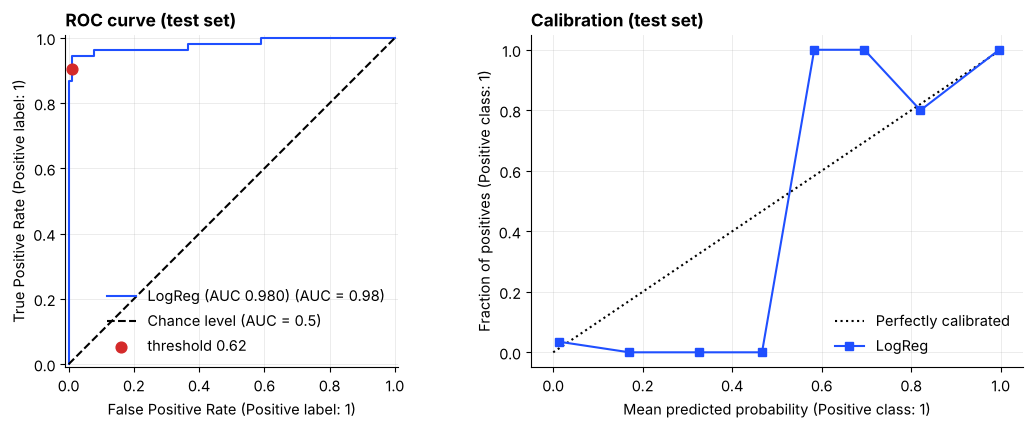

In [10]:
from sklearn.metrics import RocCurveDisplay
from sklearn.calibration import CalibrationDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[0], name=f"LogReg (AUC {roc_auc_score(y_test, p_test):.3f})",
                                 plot_chance_level=True)
axes[0].scatter(fp / (fp + tn), tp / (tp + fn), s=60, color="#d42a2a", zorder=5, label=f"threshold {threshold:.2f}")
axes[0].legend(loc="lower right"); axes[0].set_title("ROC curve (test set)")
CalibrationDisplay.from_predictions(y_test, p_test, n_bins=8, ax=axes[1], name="LogReg")
axes[1].set_title("Calibration (test set)")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.metrics import RocCurveDisplay</code></td><td>Import <code>RocCurveDisplay</code> from scikit-learn&#x27;s <code>metrics</code> module.</td></tr>
<tr><td><code>from sklearn.calibration import CalibrationDisplay</code></td><td>Import <code>CalibrationDisplay</code> from scikit-learn&#x27;s <code>calibration</code> module.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))</code></td><td>Two panels.</td></tr>
<tr><td><code>RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[0], name=f&quot;LogReg (AUC {roc_auc_score(y_test, p_test):.3f})&quot;,</code></td><td>Test ROC curve, with the AUC in the legend...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;plot_chance_level=True)</code></td><td>...and the chance diagonal.</td></tr>
<tr><td><code>axes[0].scatter(fp / (fp + tn), tp / (tp + fn), s=60, color=&quot;#d42a2a&quot;, zorder=5, label=f&quot;threshold {threshold:.2f}&quot;)</code></td><td>Mark the operating point.</td></tr>
<tr><td><code>axes[0].legend(loc=&quot;lower right&quot;); axes[0].set_title(&quot;ROC curve (test set)&quot;)</code></td><td>Legend and title.</td></tr>
<tr><td><code>CalibrationDisplay.from_predictions(y_test, p_test, n_bins=8, ax=axes[1], name=&quot;LogReg&quot;)</code></td><td>Reliability curve with 8 bins.</td></tr>
<tr><td><code>axes[1].set_title(&quot;Calibration (test set)&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 29.9 Step 9: interpretation, with stability · *Intermediate*

**Permutation importance on the test set, and coefficient stability across CV folds**

In [11]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"drop in AUC": pi.importances_mean, "sd": pi.importances_std}, index=X.columns)
print(imp.sort_values("drop in AUC", ascending=False).head(6).round(4))

cvr = cross_validate(final_model, X_train, y_train, cv=cv, return_estimator=True, n_jobs=-1)
coefs = pd.DataFrame([e.named_steps["logisticregression"].coef_[0] for e in cvr["estimator"]], columns=X.columns)
stab = pd.DataFrame({"median coef": coefs.median(), "% non-zero": (coefs != 0).mean() * 100,
                     "% positive": (coefs > 0).mean() * 100})
print(stab.reindex(coefs.median().abs().sort_values(ascending=False).index).head(8).round(2))

                         drop in AUC      sd
worst area                    0.0745  0.0168
worst radius                  0.0123  0.0069
worst texture                 0.0114  0.0067
radius error                  0.0074  0.0021
mean concavity                0.0051  0.0046
fractal dimension error       0.0031  0.0034
                      median coef  % non-zero  % positive
worst area                   4.09        92.0        92.0
worst radius                 2.07        88.0        88.0
worst texture                1.71       100.0       100.0
worst smoothness             0.98       100.0       100.0
mean concavity               0.97        88.0        88.0
worst concavity              0.59        84.0        84.0
worst concave points         0.59        88.0        88.0
radius error                 0.57        96.0        96.0


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.inspection import permutation_importance</code></td><td>Import <code>permutation_importance</code> from scikit-learn&#x27;s <code>inspection</code> module.</td></tr>
<tr><td><code>pi = permutation_importance(final_model, X_test, y_test, scoring=&quot;roc_auc&quot;, n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)</code></td><td>Shuffle each feature 30 times on the test set.</td></tr>
<tr><td><code>imp = pd.DataFrame({&quot;drop in AUC&quot;: pi.importances_mean, &quot;sd&quot;: pi.importances_std}, index=X.columns)</code></td><td>Mean and SD of the AUC drop per feature.</td></tr>
<tr><td><code>print(imp.sort_values(&quot;drop in AUC&quot;, ascending=False).head(6).round(4))</code></td><td>Top 6 features.</td></tr>
<tr><td><code>cvr = cross_validate(final_model, X_train, y_train, cv=cv, return_estimator=True, n_jobs=-1)</code></td><td>Refit on 25 resamples...</td></tr>
<tr><td><code>coefs = pd.DataFrame([e.named_steps[&quot;logisticregression&quot;].coef_[0] for e in cvr[&quot;estimator&quot;]], columns=X.columns)</code></td><td>One row of coefficients per resample.</td></tr>
<tr><td><code>stab = pd.DataFrame({&quot;median coef&quot;: coefs.median(), &quot;% non-zero&quot;: (coefs != 0).mean() * 100,</code></td><td>Median size, how often kept...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;% positive&quot;: (coefs &gt; 0).mean() * 100})</code></td><td>...and check how consistent each coefficient&#x27;s size and sign are.</td></tr>
<tr><td><code>print(stab.reindex(coefs.median().abs().sort_values(ascending=False).index).head(8).round(2))</code></td><td>The 8 features with the largest median coefficients.</td></tr>
</table>
</details>

> **📝 Note** · **Reading these results**
>
> The L1 penalty keeps *worst radius* in every resample, while near-duplicates such as *worst area* are included only some of the time (see "% non-zero"). Shuffling worst radius therefore hurts a lot, while shuffling a duplicate changes little. That does not make area irrelevant: the model only needed one member of that correlated group. Interpret importance at the level of **groups of correlated features**. In the stability table, features with the same sign in all 25 resamples are robust findings; features that appear in only some resamples (low "% non-zero") are not.

> **⚠️ Pitfall** · **The test set can disagree with your plan**
>
> The threshold was chosen to give at least 95% sensitivity on out-of-fold *training* predictions. On the test set, sensitivity came out lower (see the table above). The confidence interval is wide because there are only about 53 malignant test cases. This is exactly why you report CIs, and why you never quietly move the threshold after seeing test results. Report the shortfall honestly; if the target is critical, collect more data or validate the threshold on an independent cohort.

## 29.10 Step 10: robustness checks · *Intermediate*

**Seed sensitivity and a learning curve**

In [12]:
from sklearn.model_selection import learning_curve
seed_aucs = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
    m = GridSearchCV(pipe, grid, scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=seed), n_jobs=-1).fit(Xa, ya)
    seed_aucs.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]))
print(f"test AUC over 10 different splits: mean={np.mean(seed_aucs):.4f}, SD={np.std(seed_aucs):.4f}, "
      f"range={min(seed_aucs):.4f}–{max(seed_aucs):.4f}")
sizes, tr_s, va_s = learning_curve(final_model, X_train, y_train, cv=5, scoring="roc_auc",
                                   train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1)
print("learning curve (validation AUC):", dict(zip(sizes.tolist(), va_s.mean(axis=1).round(4).tolist())))

test AUC over 10 different splits: mean=0.9919, SD=0.0072, range=0.9740–0.9990
learning curve (validation AUC): {68: 0.9971, 136: 0.9972, 204: 0.998, 272: 0.9979, 340: 0.998}


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import learning_curve</code></td><td>Import <code>learning_curve</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>seed_aucs = []</code></td><td>Test AUC for each split seed.</td></tr>
<tr><td><code>for seed in range(10):</code></td><td>Repeat the whole split-tune-test pipeline with different seeds.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)</code></td><td>A new split.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m = GridSearchCV(pipe, grid, scoring=&quot;roc_auc&quot;, cv=StratifiedKFold(5, shuffle=True, random_state=seed), n_jobs=-1).fit(Xa, ya)</code></td><td>Re-tune on the new training part.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;seed_aucs.append(roc_auc_score(yb, m.predict_proba(Xb)[:, 1]))</code></td><td>Score on the new test part.</td></tr>
<tr><td><code>print(f&quot;test AUC over 10 different splits: mean={np.mean(seed_aucs):.4f}, SD={np.std(seed_aucs):.4f}, &quot;</code></td><td>Mean and SD across splits...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;f&quot;range={min(seed_aucs):.4f}–{max(seed_aucs):.4f}&quot;)</code></td><td>...and the full range.</td></tr>
<tr><td><code>sizes, tr_s, va_s = learning_curve(final_model, X_train, y_train, cv=5, scoring=&quot;roc_auc&quot;,</code></td><td>Training sizes and train/validation scores...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1)</code></td><td>...at 20%, 40%, ..., 100% of the training data.</td></tr>
<tr><td><code>print(&quot;learning curve (validation AUC):&quot;, dict(zip(sizes.tolist(), va_s.mean(axis=1).round(4).tolist())))</code></td><td>Training size -&gt; mean validation AUC.</td></tr>
</table>
</details>

> **🔬 Research practice** · **A results paragraph you could adapt**
>
> "Six candidate pipelines were compared using 5 × 5 repeated stratified cross-validation on the training set (n = 426). L1-regularised logistic regression performed as well as or better than the non-linear models (CV ROC AUC 0.998; Table 2) and was selected for interpretability. After tuning by grid search, the final model achieved a ROC AUC of 0.977 (95% bootstrap CI 0.944–0.999) on the held-out test set (n = 143). At a threshold pre-specified on training data to target ≥ 95% sensitivity, test sensitivity was 0.906 (0.816–0.980) and specificity 0.989 (0.965–1.000), so the sensitivity target was not met on the test set. Across ten different random splits the test AUC ranged from 0.974 to 0.999." Every number comes from the outputs above. Copy them exactly; never round in your favour, and report targets that were missed.

## 29.11 Step 11: make it reproducible · *Beginner*

**Save the model, the configuration and the environment**

In [13]:
import json, joblib, sys, sklearn, platform
joblib.dump(final_model, "final_model.joblib")
run_record = {
    "random_state": RANDOM_STATE, "threshold": threshold,
    "best_params": {k: float(v) for k, v in search.best_params_.items()},
    "test_metrics": results["estimate"].to_dict(),
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
}
with open("run_record.json", "w") as f:
    json.dump(run_record, f, indent=2)
print(json.dumps(run_record, indent=2)[:600])

{
  "random_state": 2026,
  "threshold": 0.62,
  "best_params": {
    "logisticregression__C": 1.0,
    "logisticregression__l1_ratio": 1.0
  },
  "test_metrics": {
    "ROC AUC": 0.98,
    "Sensitivity": 0.906,
    "Specificity": 0.989,
    "Balanced acc.": 0.947,
    "Brier score": 0.032
  },
  "versions": {
    "python": "3.13.18",
    "numpy": "2.5.3",
    "pandas": "3.0.5",
    "scikit-learn": "1.9.1"
  }
}


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import json, joblib, sys, sklearn, platform</code></td><td>Import the standard-library <code>json</code> module and joblib, used to save and load fitted models and the <code>sys</code> module (interpreter information) and scikit-learn and the <code>platform</code> module (system and version info).</td></tr>
<tr><td><code>joblib.dump(final_model, &quot;final_model.joblib&quot;)</code></td><td>Save the final fitted pipeline.</td></tr>
<tr><td><code>run_record = {</code></td><td>Everything needed to reproduce and report the run:</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;random_state&quot;: RANDOM_STATE, &quot;threshold&quot;: threshold,</code></td><td>The seed and the operating threshold.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;best_params&quot;: {k: float(v) for k, v in search.best_params_.items()},</code></td><td>Chosen hyperparameters.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;test_metrics&quot;: results[&quot;estimate&quot;].to_dict(),</code></td><td>Test metrics.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;versions&quot;: {&quot;python&quot;: platform.python_version(), &quot;numpy&quot;: np.__version__,</code></td><td>Software versions...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;pandas&quot;: pd.__version__, &quot;scikit-learn&quot;: sklearn.__version__},</code></td><td>...continued.</td></tr>
<tr><td><code>}</code></td><td>Close the dictionary opened above.</td></tr>
<tr><td><code>with open(&quot;run_record.json&quot;, &quot;w&quot;) as f:</code></td><td>Open the output file.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;json.dump(run_record, f, indent=2)</code></td><td>Write it as readable JSON.</td></tr>
<tr><td><code>print(json.dumps(run_record, indent=2)[:600])</code></td><td>Show the start of the record.</td></tr>
</table>
</details>

> **✍️ Try it yourself**
>
> 1. Re-run the protocol with `HistGradientBoostingClassifier` as the primary model. Is the conclusion different?
> 2. Replace the hold-out test set by nested cross-validation ([Chapter 23](../part-5-scikit-learn/23-sklearn-model-selection.ipynb)) and compare the estimates.
> 3. Write the Methods paragraph for this study using the checklist in [Chapter 31](31-research-reporting.ipynb).
>
> *Worked solutions:* [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 29*.

---

⬅️ [Chapter 28: Deep learning architectures: CNNs, sequence models and custom training](../part-6-tensorflow-keras/28-keras-advanced.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 30: Choosing models and metrics, and comparing them rigorously](30-research-choosing.ipynb) ➡️